In [1]:
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel
import torch
import cv2
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

C:\Users\Stefano\anaconda3\envs\GenAi\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [107]:
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-scribble",
    torch_dtype=torch.float16
).to("cuda")

pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    controlnet=controlnet,
    safety_checker=None,
    torch_dtype=torch.float16
).to("cuda")


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Loading pipeline components...: 100%|████████████| 6/6 [00:01<00:00,  3.93it/s]
You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


In [108]:
def load_sketch(path):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img = cv2.resize(img, (512, 512))
    img = cv2.Canny(img, 250 ,250)
    img = Image.fromarray(img)
    return img


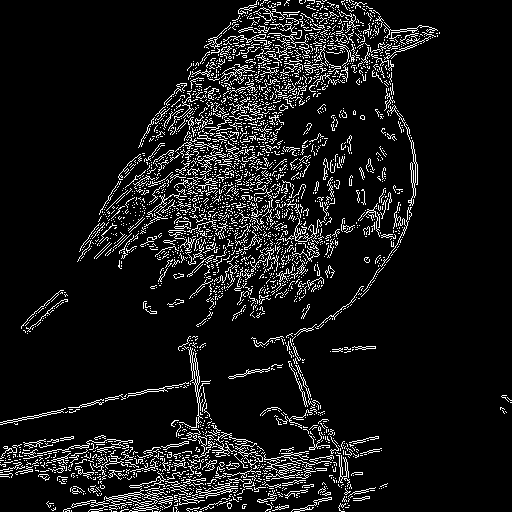

In [109]:
load_sketch("control_bird_canny.png")

In [110]:
def generate_controlnet(sketch_path, prompt="a realistic version the sketch"):
    sketch = load_sketch(sketch_path)

    negative_prompt = (
        "metal, glossy, plastic, alien texture, creepy, horror, shiny skin, scales, armor, robotic, "
        "deformed, blur, noise, extra limbs, distorted colors"
    )
    result = pipe(
        prompt,
        negative_prompt=negative_prompt,
        image=sketch,
        num_inference_steps=200,
        guidance_scale=10,
        controlnet_conditioning_scale=1.2
    )

    return result.images[0]


In [ ]:
prompt = (
    "Photorealistic image of a bird")

100%|████████████████████████████████████████| 200/200 [00:15<00:00, 12.77it/s]


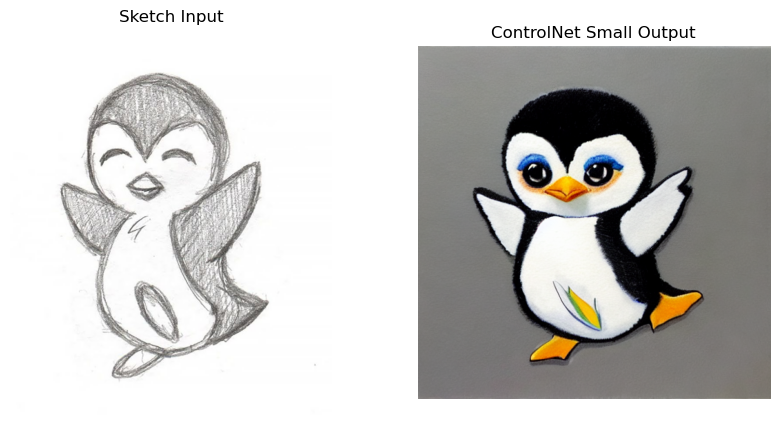

In [112]:
sketch_path = "sketch.jpg"

output = generate_controlnet(sketch_path, prompt=prompt)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.title("Sketch Input")
plt.imshow(Image.open(sketch_path))
plt.axis("off")

plt.subplot(1,2,2)
plt.title("ControlNet Small Output")
plt.imshow(output)
plt.axis("off")

plt.show()
